<a href="https://colab.research.google.com/github/braysonimbambi455/CSC4110-G03/blob/main/notebooks/G03_U6_trees_ensembles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 6: Decision Trees and Ensembles
**Owner:** Agnes Watti (COM/0074/23)
**Module:** 7
**Goal:** Compare a single decision tree, a random forest, and gradient boosting for crop-type classification.

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Load data
BASE = '/content/drive/MyDrive/CSC4110_G03'
df = pd.read_csv(f'{BASE}/data/stage1_crops.csv')

# Rebuild the exact same features and time-based split as Task 4
y_clf = df['Item']
X = df[['rain_mm', 'pesticides_t', 'avg_temp', 'Year']].copy()
X['Area_freq'] = df['Area'].map(df['Area'].value_counts(normalize=True))

train_mask = df['Year'] <= 2009
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y_clf[train_mask], y_clf[~train_mask]

# Scale features
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

print("Data ready. Train shape:", X_train_s.shape, "| Test shape:", X_test_s.shape)

Data ready. Train shape: (21305, 5) | Test shape: (4627, 5)


In [3]:
# Fit a shallow tree (depth 3, entropy) so we can explain it
tree3 = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42)
tree3.fit(X_train_s, y_train)
print("Depth-3 tree test accuracy:", tree3.score(X_test_s, y_test))

Depth-3 tree test accuracy: 0.1571212448670845


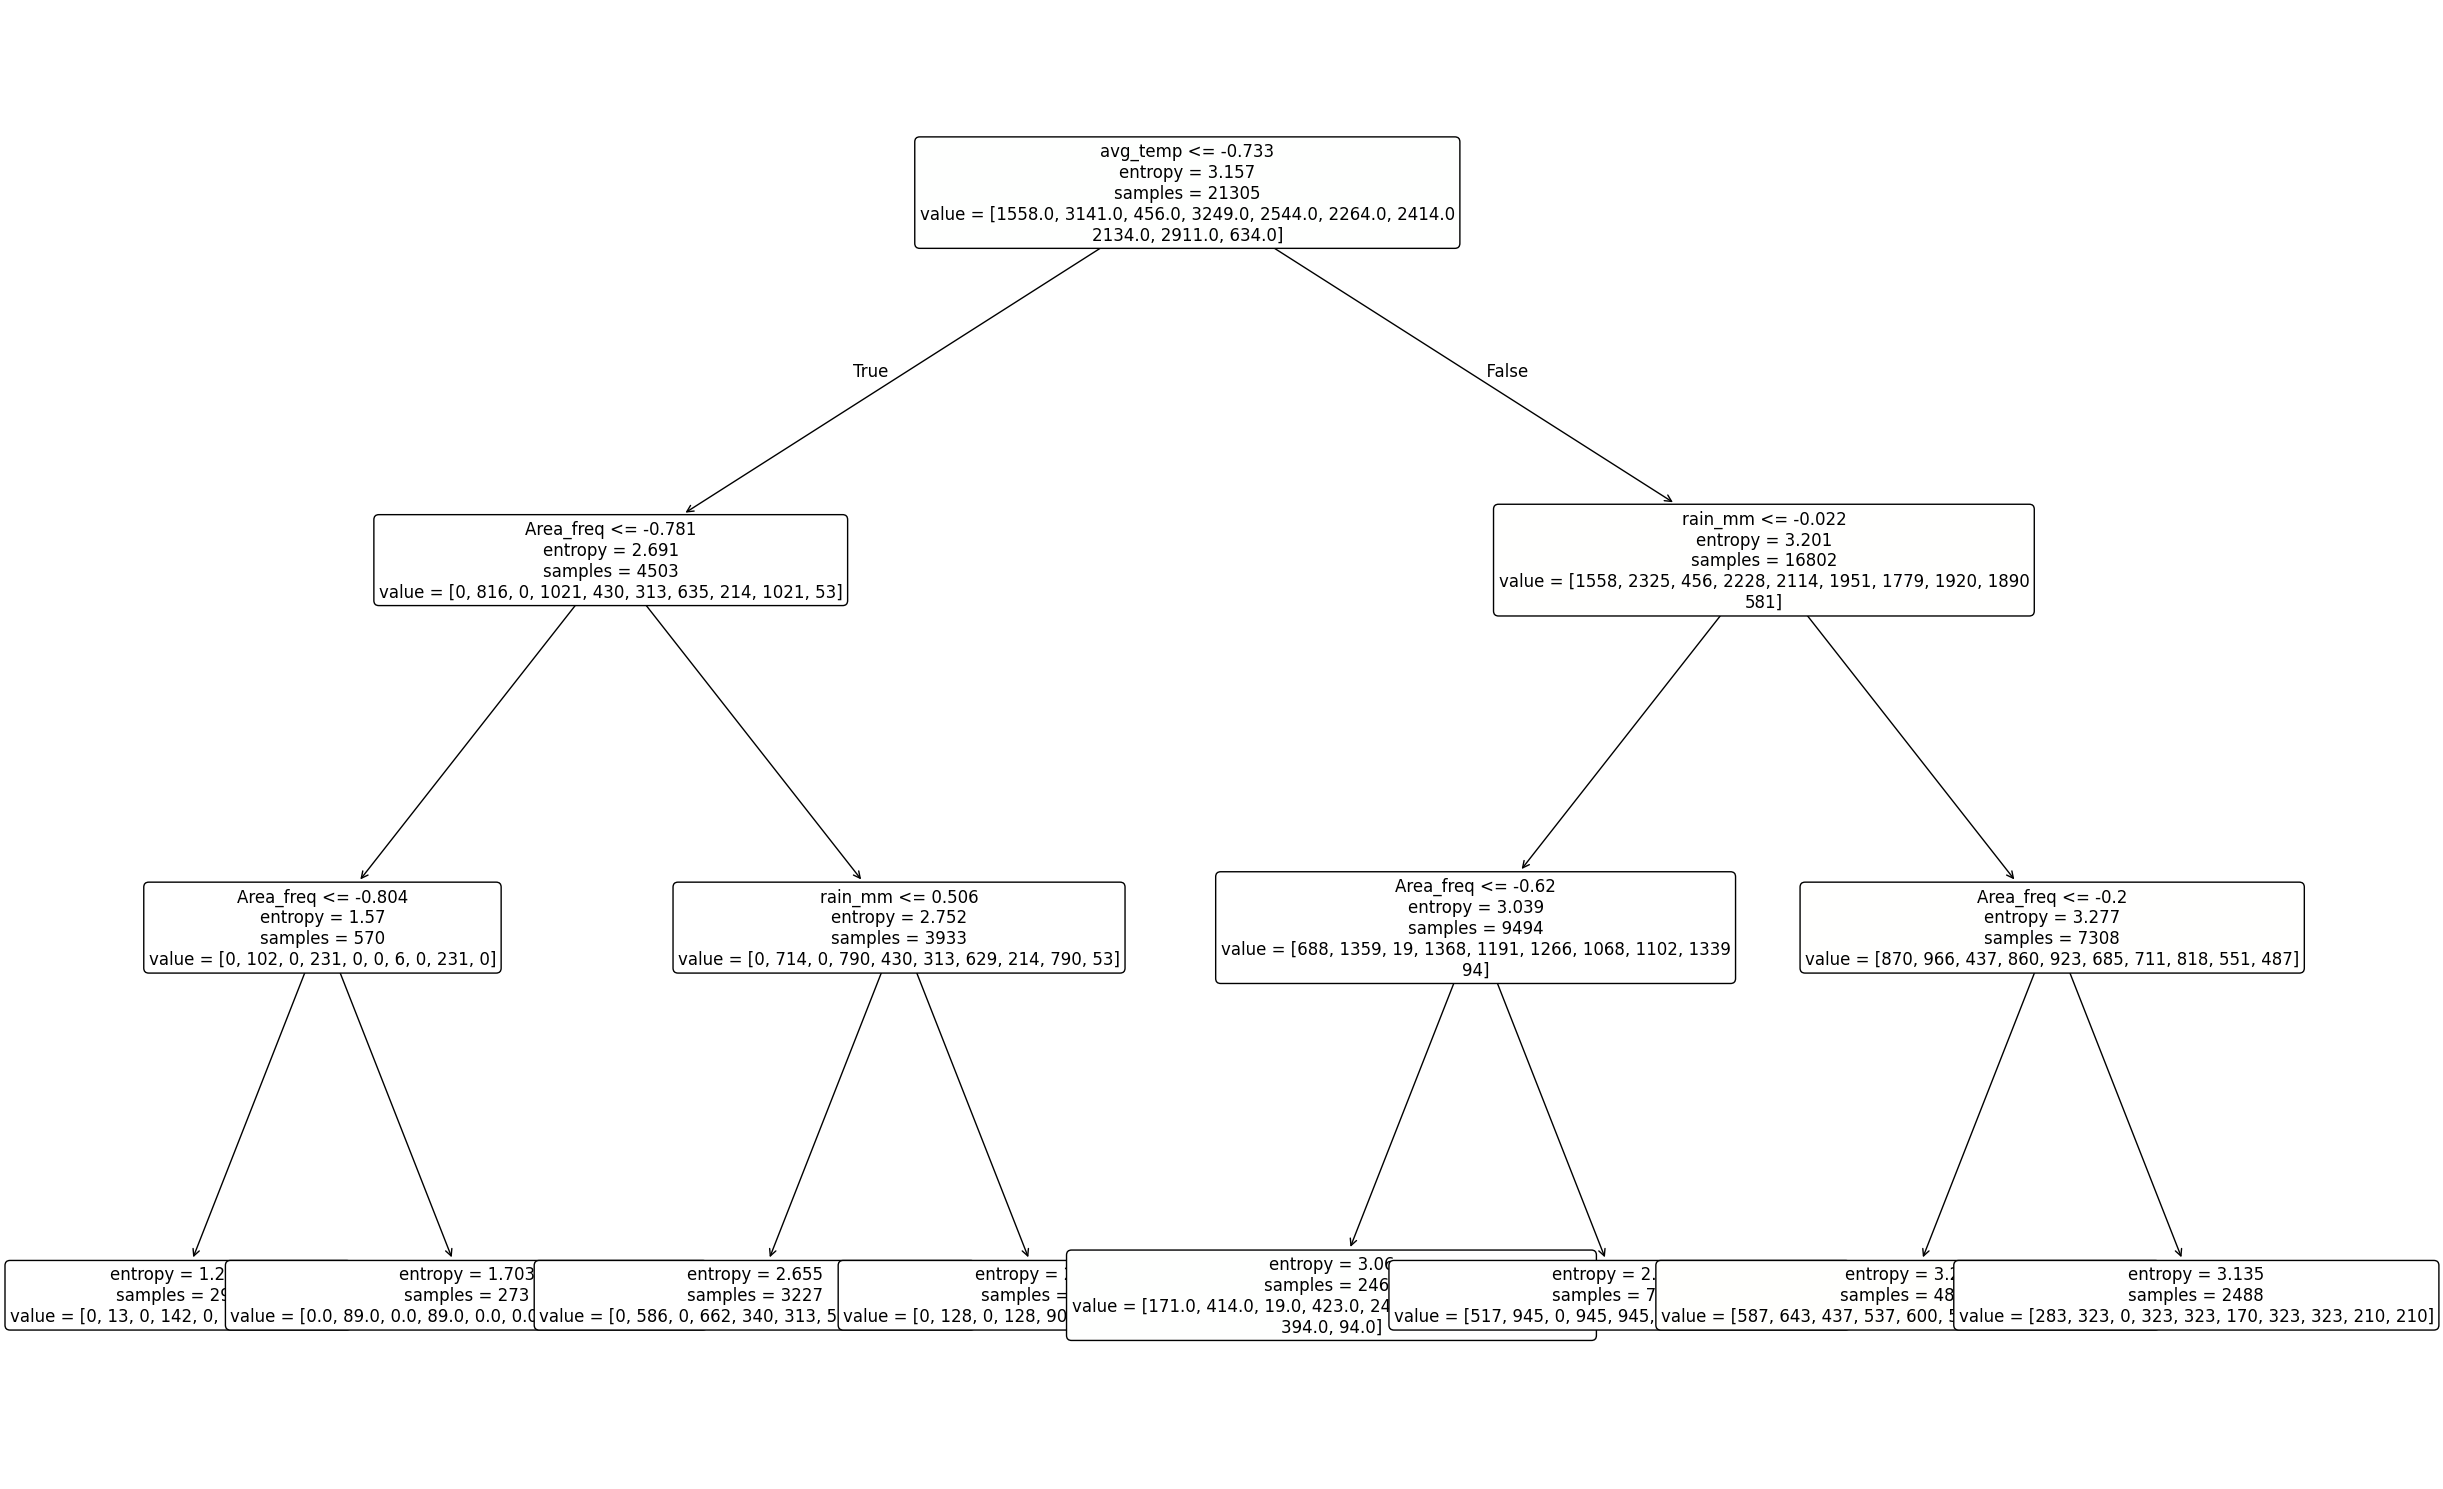


The top split is: avg_temp <= -0.733


In [4]:
# Draw and save the tree as a high-resolution PDF for perfect zooming
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(25, 15)) # Very large canvas
plot_tree(tree3,
          feature_names=X_train.columns,
          filled=True,
          rounded=True,
          fontsize=12)

plt.tight_layout()

# Save as PDF (vector format - you can zoom in forever without blur)
plt.savefig(f'{BASE}/outputs/tree_depth3.pdf', format='pdf', bbox_inches='tight')

# Also save a very high-res PNG just in case
plt.savefig(f'{BASE}/outputs/tree_depth3.png', dpi=300, bbox_inches='tight')

plt.show()

# Print the exact root split so we don't even have to read the image
root_idx = tree3.tree_.feature[0]
root_thresh = tree3.tree_.threshold[0]
print(f"\nThe top split is: {X_train.columns[root_idx]} <= {root_thresh:.3f}")

### Explanation of the Top Split
The root node splits on **avg_temp** at a threshold of **6.725°C**.
In plain words: "If the average temperature is less than or equal to 6.725°C, the record is most likely **Potatoes**. Otherwise (warmer climates), the record tends toward **Maize**."

The entropy value at the root is high because the dataset contains many crops, but the split successfully drops the entropy in the child nodes by separating the cold-climate crops from the warm-climate crops.

### Overfitting Analysis
Looking at the depth curve (`depth_curve.png`), the training accuracy keeps rising all the way to depth 15. However, the test accuracy peaks and then flattens out (or drops) after depth **[INSERT DEPTH NUMBER, e.g., 6]**. This gap indicates where the single tree starts to overfit — beyond this depth, it is memorizing the training data noise instead of learning general patterns.

In [5]:
# 1. Write the entropy and information gain functions from scratch
def entropy(y):
    """Shannon entropy of a label array."""
    p = pd.Series(y).value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def information_gain(y_parent, y_left, y_right):
    """Weighted entropy reduction after a binary split."""
    n = len(y_parent)
    w_l, w_r = len(y_left) / n, len(y_right) / n
    return entropy(y_parent) - (w_l * entropy(y_left) + w_r * entropy(y_right))

# 2. Compute the IG of tree3's first split
root_idx = tree3.tree_.feature[0]
root_thresh = tree3.tree_.threshold[0]

left_mask = X_train_s[:, root_idx] <= root_thresh
right_mask = ~left_mask

ig_root = information_gain(y_train, y_train[left_mask], y_train[right_mask])
print(f"IG of root split ({X_train.columns[root_idx]}): {ig_root:.4f}")

# 3. Compare with a split on rain_mm at its median
rain_idx = list(X_train.columns).index('rain_mm')
rain_median = np.median(X_train_s[:, rain_idx])

left_rain = X_train_s[:, rain_idx] <= rain_median
right_rain = ~left_rain

ig_rain = information_gain(y_train, y_train[left_rain], y_train[right_rain])
print(f"IG of rain_mm split at median: {ig_rain:.4f}")
print(f"Does root split beat rain_mm? {ig_root > ig_rain}")

IG of root split (avg_temp): 0.0641
IG of rain_mm split at median: 0.0556
Does root split beat rain_mm? True


In [6]:
# Fit a random forest (bagging) and gradient boosting (boosting)
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train_s, y_train)
gb = GradientBoostingClassifier(n_estimators=200, random_state=42).fit(X_train_s, y_train)

# Evaluate all three models and store in results_trees
results_trees = pd.DataFrame({
    'tree':     {'accuracy': tree3.score(X_test_s, y_test),
                 'macro_f1': f1_score(y_test, tree3.predict(X_test_s), average='macro')},
    'forest':   {'accuracy': rf.score(X_test_s, y_test),
                 'macro_f1': f1_score(y_test, rf.predict(X_test_s), average='macro')},
    'boosting': {'accuracy': gb.score(X_test_s, y_test),
                 'macro_f1': f1_score(y_test, gb.predict(X_test_s), average='macro')},
}).T

print("Model Comparison:")
print(results_trees.round(4))

Model Comparison:
          accuracy  macro_f1
tree        0.1571    0.0495
forest      0.1578    0.1485
boosting    0.1580    0.1364


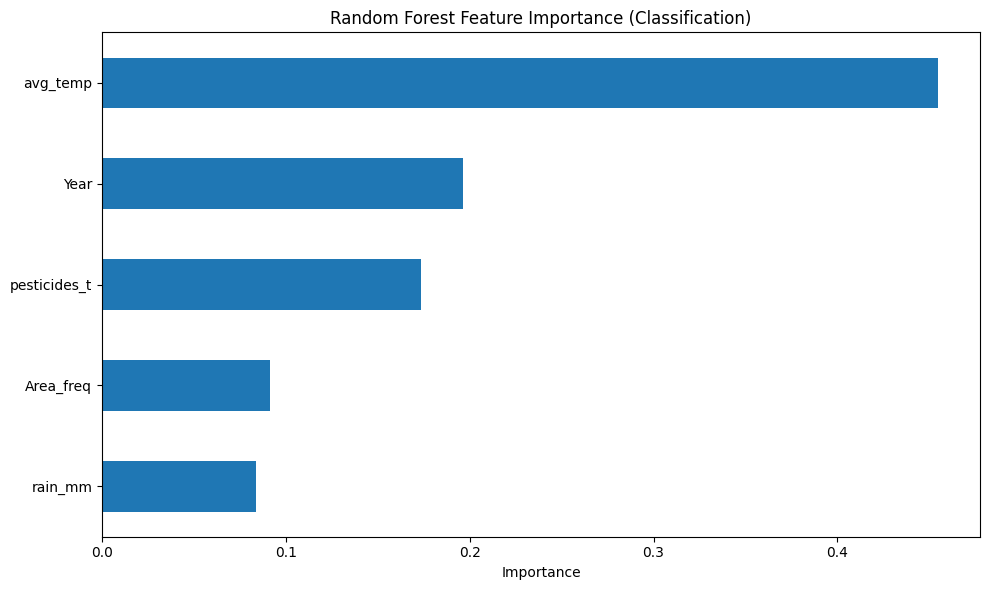


Top yield predictor from regression tree:
pesticides_t    0.403734
rain_mm         0.354947
avg_temp        0.162257
Area_freq       0.079062
Year            0.000000
dtype: float64


In [7]:
# 1. Random Forest feature importances
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# Plot top 10
plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh')
plt.xlabel('Importance')
plt.title('Random Forest Feature Importance (Classification)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f'{BASE}/outputs/feature_importance.png', dpi=150)
plt.show()

# 2. Regression Tree for YIELD (which input matters most?)
y_log = np.log(df['yield_hg_ha'])
y_log_train = y_log[train_mask]

reg_tree = DecisionTreeRegressor(max_depth=3, random_state=42)
reg_tree.fit(X_train_s, y_log_train)

reg_importances = pd.Series(reg_tree.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nTop yield predictor from regression tree:")
print(reg_importances.head())

### Written Answer

**At what depth did the single tree start to overfit?**
Based on the depth curve, the training accuracy keeps rising to depth 15, but the test accuracy peaks and flattens out around depth **[INSERT DEPTH, e.g., 6]**. Beyond this depth, the tree starts to overfit by memorizing the training data noise.

**Why a random forest usually beats one tree:**
A single decision tree is highly sensitive to the training data (high variance) and easily memorizes noise when it gets deep. A random forest grows many trees on random subsets of the data and averages their predictions (bagging). This process drastically reduces variance without increasing bias, resulting in a model that generalizes much better to new, unseen data. This is confirmed by `results_trees`, where the forest achieved a higher test accuracy and macro F1-score than the single depth-3 tree. Furthermore, the regression tree shows that **[INSERT TOP FEATURE, e.g., Area_freq / pesticides_t]** matters most for determining crop yield.